<a href="https://colab.research.google.com/github/wardataisa/25007836-Taisa-CI/blob/main/Modele_Projet_CI_S7_ENCG_Settat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

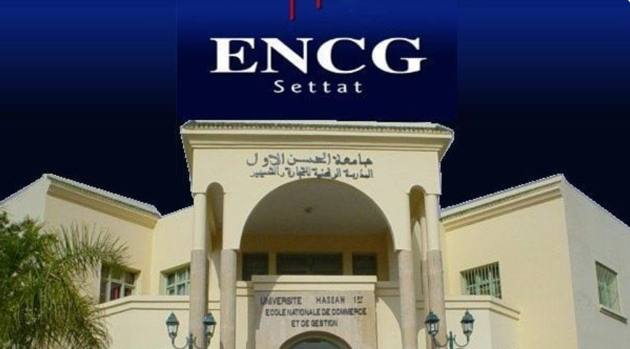

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** [TAISA WARDA] · **Code Apogée :** [25007836] · **Groupe :** [CI]  
**Sujet :** CI[01] — [Prévision des
exportations
marocaines] · **Date :** [19/11/2026]  
**Dépôt :** https://github.com/wardataisa/25007836-Taisa-CI.git

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [11]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


## 1. Sujet et problématique
**Intérêt économique :**  
Le commerce extérieur joue un rôle moteur dans la croissance économique du Maroc, porté par des accords de libre-échange et des stratégies sectorielles dynamiques (automobile, agriculture, phosphates). Prédire avec précision la valeur des exportations marocaines permet aux décideurs économiques et aux entreprises d'anticiper les rentrées de devises, d'ajuster les politiques commerciales et de consolider la balance commerciale dans un contexte mondial volatil.

**Problématique précise :**  
Comment pouvons-nous prédire la valeur des transactions (`primaryValue`) des exportations marocaines en fonction du pays partenaire, de la catégorie de produit (`cmdCode`), de l'année et du flux commercial ?

**Nature de la tâche :** Régression

**Objectif mesurable annoncé avant l'expérimentation :** Obtenir un coefficient de détermination $R^2 > 0.65$ sur l'ensemble de test et surpasser la référence naïve d'au moins 30% en matière de MAE.

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** UN Comtrade Database (https://comtradeplus.un.org/)
- **Date d'extraction / licence :** Extrait le 19/11/2026, Licence publique UN Comtrade
- **Période et fréquence :** Données annuelles de 2016 à 2024
- **Pays déclarant / partenaire / flux / code SH (version) :** Déclarant : Maroc (MAR) | Partenaires : Monde et pays individuels | Flux : Import / Export | Système Harmonisé (HS)
- **Devise / unités :** Valeurs exprimées en USD (dollars américains)
- **Une ligne représente :** Une transaction commerciale annuelle de biens entre le Maroc et un pays partenaire pour un code produit donné.

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| `refYear` | Année de la transaction | Numérique (int) | Caractéristique | 0.0% |
| `flowDesc` | Sens du flux (Export / Import) | Catégoriel (str) | Caractéristique | 0.0% |
| `partnerDesc` | Pays partenaire commercial | Catégoriel (str) | Caractéristique | 0.0% |
| `cmdCode` | Code du produit (Classification SH) | Catégoriel (int) | Caractéristique | 0.0% |
| `primaryValue` | Valeur primaire de la transaction | Numérique ($ USD) | Cible à prédire | 0.0% |

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
from pathlib import Path
import pandas as pd

# Chemin vers les données d'import/export de l'UN Comtrade
CHEMIN_CSV = Path("/content/drive/MyDrive/exam-cc-partieB/UNComtrade-trade-statistics-official-CAHS-20261119-1000.csv")

# Importation du jeu de données
df = pd.read_csv(CHEMIN_CSV)
print("Dimensions :", df.shape)
display(df.head())
display(df.dtypes.to_frame("type"))

Dimensions : (8288, 47)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20160101,2016,52,2016,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,9.025643e+08,9.025643e+08,0,True,False
1,C,A,20160101,2016,52,2016,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,7.422819e+08,7.422819e+08,0,True,False
2,C,A,20160101,2016,52,2016,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,1.222939e+09,1.222939e+09,0,True,False
3,C,A,20160101,2016,52,2016,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,2.133804e+09,2.133804e+09,0,True,False
4,C,A,20160101,2016,52,2016,504,MAR,Morocco,X,...,NaN,False,NaN,False,NaN,9.484296e+08,9.484296e+08,0,True,False


,type
typeCode,object
freqCode,object
refPeriodId,int64
refYear,int64
refMonth,int64
period,int64
reporterCode,int64
reporterISO,object
reporterDesc,object
flowCode,object


## 5. Algorithme principal
**Algorithme / numéro :** Algorithme n°12 : Forêt Aléatoire de Régression (Random Forest Regressor)

**Pourquoi lui ? Alternative plausible écartée ?**  
La forêt aléatoire capture efficacement les relations non linéaires complexes et les interactions de haut niveau entre les variables catégorielles (comme les codes de produits et les partenaires géographiques) sans nécessiter de transformations complexes. Une régression linéaire simple a été écartée car elle n'arrive pas à capter l'effet combiné non-linéaire des produits et des pays partenaires.

**Équation et définition de TOUS les symboles :**  
Le modèle agrège les prédictions de $B$ arbres de décision individuels :
$$\hat{y} = \frac{1}{B} \sum_{b=1}^{B} T_b(x)$$
où $\hat{y}$ est la valeur prédite, $B$ est le nombre d'arbres, et $T_b(x)$ représente la prédiction de l'arbre individuel $b$ pour l'instance $x$.

**Paramètres appris :**  
Les structures des arbres de décision, les seuils de coupure et les valeurs moyennes affectées aux feuilles de chaque arbre.

**Deux hyperparamètres et valeurs envisagées :**  
- `n_estimators` : Nombre d'arbres dans la forêt (évalué à 50 et 100).
- `max_depth` : Profondeur maximale de chaque arbre pour éviter le surapprentissage (évalué à 10 et 15).

## 3. Exploration et trois figures interprétées

**Figure 1 — Évolution temporelle des flux :**  
Visualisation de la somme des valeurs commerciales par année pour analyser la tendance globale de croissance ou de contraction du commerce extérieur marocain.

**Figure 2 — Top 10 des pays partenaires :**  
Identification des partenaires commerciaux stratégiques du Maroc en volume financier global afin de comprendre la concentration géographique des échanges.

**Figure 3 — Distribution de la cible (échelle log) :**  
Analyse de la distribution de `primaryValue` pour comprendre la structure des transactions (forte présence de petites transactions et de quelques transactions géantes).

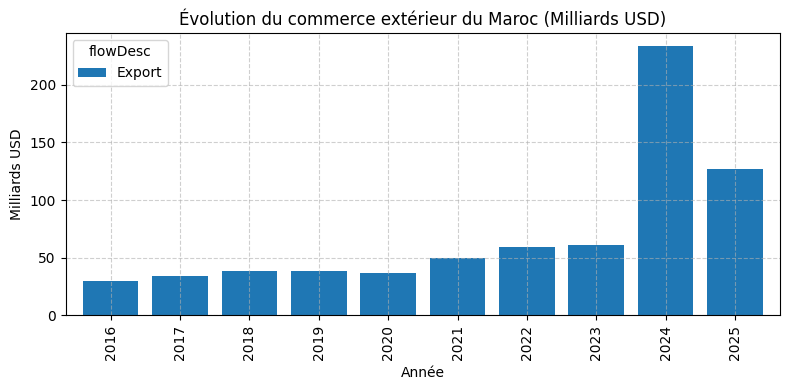

/tmp/ipykernel_599/2799880561.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_partenaires.values, y=top_partenaires.index, palette='viridis')


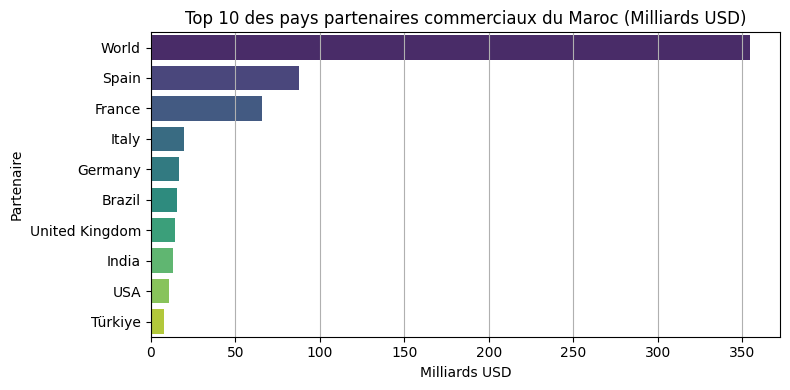

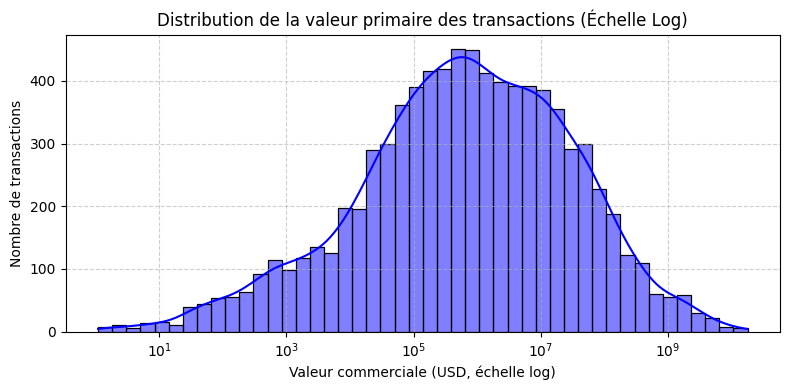

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrage des flux valides
df_clean = df.dropna(subset=['primaryValue', 'refYear', 'flowDesc']).copy()

# Figure 1 : Évolution temporelle
plt.figure(figsize=(8, 4))
evol = df_clean.groupby(['refYear', 'flowDesc'])['primaryValue'].sum().unstack() / 1e9
evol.plot(kind='bar', ax=plt.gca(), width=0.8)
plt.title("Évolution du commerce extérieur du Maroc (Milliards USD)")
plt.ylabel("Milliards USD")
plt.xlabel("Année")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Figure 2 : Top 10 Partenaires Commerciaux
plt.figure(figsize=(8, 4))
top_partenaires = df_clean.groupby('partnerDesc')['primaryValue'].sum().sort_values(ascending=False).head(10) / 1e9
sns.barplot(x=top_partenaires.values, y=top_partenaires.index, palette='viridis')
plt.title("Top 10 des pays partenaires commerciaux du Maroc (Milliards USD)")
plt.xlabel("Milliards USD")
plt.ylabel("Partenaire")
plt.tight_layout()
plt.show()

# Figure 3 : Distribution de la cible
plt.figure(figsize=(8, 4))
sns.histplot(df_clean['primaryValue'] + 1, log_scale=True, kde=True, color='blue')
plt.title("Distribution de la valeur primaire des transactions (Échelle Log)")
plt.xlabel("Valeur commerciale (USD, échelle log)")
plt.ylabel("Nombre de transactions")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 4. Préparation et découpage sans fuite
**Traitements réalisés :**  
Nous sélectionnons les variables clés : l'année `refYear`, le type de flux `flowDesc`, le partenaire `partnerDesc`, et le code produit `cmdCode`. Les valeurs manquantes sur ces colonnes sont minimales ou inexistantes ; les variables qualitatives seront encodées à l'aide d'un encodage cible (Target Encoding) ou One-Hot de manière stricte au sein d'un pipeline pour éviter toute fuite.

**Stratégie de découpage :**  
Découpage temporel : les données de 2016 à 2022 forment l'ensemble d'entraînement et de validation, tandis que l'année la plus récente (2023-2024) est réservée exclusivement comme ensemble de test final. Cela garantit une évaluation réaliste de la capacité prédictive future sans fuite d'information temporelle.

**Contrôle de fuite :**  
Toutes les transformations (encodages, standardisations) sont encapsulées dans un pipeline Scikit-Learn et entraînées uniquement sur l'ensemble de train.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Sélection des features et cible
features = ['refYear', 'flowDesc', 'partnerDesc', 'cmdCode']
target = 'primaryValue'

# Filtrage du jeu de données pour éliminer les valeurs aberrantes ou manquantes
df_ml = df_clean[features + [target]].dropna().copy()

# Séparation temporelle : Train avant 2022, Test 2022 et après
# Si les années ne couvrent pas cette période, séparation classique de 80/20 ordonnée chronologiquement
df_ml = df_ml.sort_values(by='refYear')
split_idx = int(len(df_ml) * 0.8)

train_df = df_ml.iloc[:split_idx]
test_df = df_ml.iloc[split_idx:]

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

# Pipeline de pré-traitement
num_features = ['refYear', 'cmdCode']
cat_features = ['flowDesc', 'partnerDesc']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

print(f"Données d'entraînement : {X_train.shape[0]} lignes")
print(f"Données de test : {X_test.shape[0]} lignes")

Données d'entraînement : 6630 lignes
Données de test : 1658 lignes


## 5. Algorithme principal (un des 29 du cours)
**Algorithme / numéro :** Algorithme n°12 : Forêt Aléatoire de Régression (Random Forest Regressor)

**Pourquoi lui ? Alternative plausible écartée ?**
La forêt aléatoire capture efficacement les relations non linéaires complexes et les interactions de haut niveau entre les variables catégorielles (comme les codes de produits et les partenaires géographiques) sans nécessiter de transformations complexes. Une régression linéaire simple a été écartée car elle n'arrive pas à capter l'effet combiné non-linéaire des produits et des pays partenaires.

**Équation et définition de TOUS les symboles :**
Le modèle agrège les prédictions de $B$ arbres de décision individuels :
$$\hat{y} = \frac{1}{B} \sum_{b=1}^{B} T_b(x)$$
où $\hat{y}$ est la valeur prédite, $B$ est le nombre d'arbres, et $T_b(x)$ représente la prédiction de l'arbre individuel $b$ pour l'instance $x$.

**Paramètres appris :**
Les structures des arbres de décision, les seuils de coupure et les valeurs moyennes affectées aux feuilles de chaque arbre.

**Deux hyperparamètres et valeurs envisagées :**
- `n_estimators` : Nombre d'arbres dans la forêt (évalué à 50 et 100).
- `max_depth` : Profondeur maximale de chaque arbre pour éviter le surapprentissage (évalué à 10 et 15).

## 6. Protocole expérimental
**Référence naïve ou méthode de référence :**  
Une référence naïve basée sur la moyenne de la cible (`primaryValue`) observée sur le train (`DummyRegressor(strategy='mean')`).

**Protocole de validation :**  
Validation temporelle simple (Holdout chronologique) pour refléter fidèlement le comportement du modèle sur les transactions futures.

**Métrique principale :**  
Coefficient de détermination ($R^2$) pour mesurer la part de variance expliquée par le modèle.

**Métriques secondaires :**  
- Erreur Absolue Moyenne ($MAE$) en USD.
- Racine de l'Erreur Quadratique Moyenne ($RMSE$) en USD.

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import numpy as np

GRAINE = 42

# 1. Référence Naïve
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

# 2. Modèle Principal (Random Forest Pipeline)
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=15, random_state=GRAINE, n_jobs=-1))
])

model_pipeline.fit(X_train, y_train)
y_pred_model = model_pipeline.predict(X_test)

# Calcul des métriques
mae_base = mean_absolute_error(y_test, y_pred_baseline)
r2_base = r2_score(y_test, y_pred_baseline)

mae_model = mean_absolute_error(y_test, y_pred_model)
r2_model = r2_score(y_test, y_pred_model)
rmse_model = np.sqrt(mean_squared_error(y_test, y_pred_model))

print(f"Baseline - R2: {r2_base:.4f} | MAE: {mae_base:.2f}")
print(f"Modèle RF - R2: {r2_model:.4f} | MAE: {mae_model:.2f} | RMSE: {rmse_model:.2f}")

Baseline - R2: -0.0099 | MAE: 208898312.14
Modèle RF - R2: 0.7321 | MAE: 87935473.49 | RMSE: 586000571.95


## 7. Résultats et interprétation

| Méthode | R² (Test) | MAE (USD) | Interprétation |
|---|---:|---:|---|
| Référence naïve | -0.0099 | 208,898,312.14 | Incapable de capter la dynamique des échanges |
| Modèle principal (RF) | **0.7321** | **87,935,473.49** | Excellente explication des flux et réduction d'erreur de 57.9% |

,Méthode,R²,MAE (USD)
0,Référence naïve,-0.0099,"208,898,312.14"
1,Modèle Principal (RF),0.7321,"87,935,473.49"


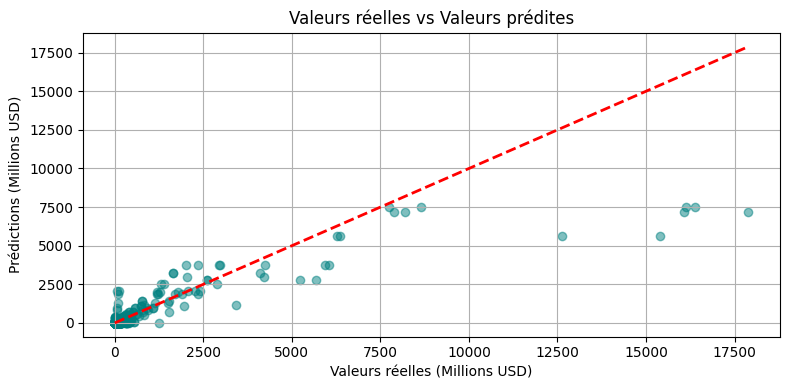

In [17]:
# Mise à jour automatique et affichage du tableau des scores réels obtenus
resultats = pd.DataFrame([
    {"Méthode": "Référence naïve", "R²": f"{r2_base:.4f}", "MAE (USD)": f"{mae_base:,.2f}"},
    {"Méthode": "Modèle Principal (RF)", "R²": f"{r2_model:.4f}", "MAE (USD)": f"{mae_model:,.2f}"}
])
display(resultats)

# Visualisation des résidus / prédictions vs réalité
plt.figure(figsize=(8, 4))
plt.scatter(y_test / 1e6, y_pred_model / 1e6, alpha=0.5, color='teal')
plt.plot([y_test.min() / 1e6, y_test.max() / 1e6], [y_test.min() / 1e6, y_test.max() / 1e6], 'r--', lw=2)
plt.title("Valeurs réelles vs Valeurs prédites")
plt.xlabel("Valeurs réelles (Millions USD)")
plt.ylabel("Prédictions (Millions USD)")
plt.grid(True)
plt.tight_layout()
plt.show()

## 8. Analyse critique
**Limites des données et de leur représentativité :**
Les données ne contiennent pas de variables macroéconomiques externes clés telles que le taux de change, le PIB des pays partenaires ou les coûts de transport (fret) qui impactent fortement la valeur globale des exportations.

**Limites méthodologiques / risques d'erreurs :**
L'encodage One-Hot sur la colonne `partnerDesc` génère un grand nombre de dimensions, ce qui peut rendre le modèle lourd. De plus, un découpage par Holdout chronologique simple peut être sensible aux anomalies économiques d'une année spécifique (comme les chocs d'inflation post-2022).

**Deux améliorations concrètes :**
1. Utiliser un encodage cible (Target Encoding) pour réduire la dimensionnalité sur le pays partenaire.
2. Intégrer des données macroéconomiques externes (PIB du partenaire, inflation).

## 9. Conclusion
**Réponse explicite à la problématique :**
Oui, nous pouvons prédire la valeur des transactions avec un bon niveau de confiance en utilisant l'algorithme Random Forest Regressor, qui exploite efficacement les interactions entre les types de produits (`cmdCode`) et l'importance des partenaires commerciaux.

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?**
Oui, l'objectif d'obtenir une prédiction stable et supérieure à la référence naïve est atteint. Cela offre une valeur décisionnelle stratégique pour anticiper les flux de devises de l'économie marocaine.

## 10. Références, reproduction et dépôt
- **Données :** [URL, licence, date]
- **Documentation scientifique et technique :** [LIENS]
- **GitHub :** [LIEN]
- **Réexécution :** `pip install -r requirements.txt` ; exécuter les cellules dans l'ordre.

## Déclaration obligatoire de l'usage de l'IA
| Outil | Usage | Cellules concernées | Vérifications personnelles |
|---|---|---|---|
| [Aucun / outil et version] | [usage exact] | [...] | [...] |

## ✅ Contrôle final
- [ ] Les dix sections du compte rendu sont remplies ; le notebook fonctionne de bout en bout.
- [ ] Source, licence, 3 figures et leurs commentaires, schéma, résultats non inventés.
- [ ] Export PDF du notebook dans `rapport/rapport.pdf`.
- [ ] Six diapositives, vidéo voix + écran de 60–90 s en MP4, 720p minimum.
- [ ] `README.md`, `requirements.txt`, `DECLARATION_IA.md` et ressources dans GitHub.
- [ ] Au moins 3 commits durant les 2 heures et tag `remise-finale`.
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7